# Benchmark indipendente dei metodi di ordinamento ordinale

Il notebook confronta O-MiniRocket con un ordine Band power fissato a priori, una baseline Random order e quattro tecniche apprese dai fold di training. Ogni metodo ha una propria cella di addestramento/test: dopo la configurazione iniziale si può eseguire indipendentemente solo la cella desiderata.

Il riferimento MiniRocket nominale viene letto dagli artefatti già esistenti e non viene riaddestrato. Tutti i metodi ordinali vengono invece addestrati e valutati in questa cartella con gli stessi 10 split stratificati. I risultati possono essere salvati esclusivamente come CSV e PNG dentro `ordinal_ordering_benchmark/results`.


## Quick test end-to-end

Imposta `QUICK_TEST = True` nella cella di configurazione per eseguire una prova breve senza l'intero benchmark: usa un solo dataset, solo i primi fold esterni, pochi seed casuali e pochi campioni bootstrap. Il quick test conserva output separati in `results/quick_smoke` e non sovrascrive i risultati completi. Imposta `QUICK_TEST = False` per tornare ai due dataset, 10 fold, 20 seed casuali e 10.000 bootstrap resamples.


## Configurazione generale e modelli

La cella prepara soltanto percorsi, dati, seed e funzioni. Non addestra ancora alcun metodo. MiniRocket produce una rappresentazione numerica dei segnali; per O-MiniRocket la previsione usa una decomposizione binaria ordinale con **K−1 RidgeClassifierCV binari**. Il classificatore nominale di riferimento, quando serve alla costruzione dell'ordine confusion-based, è un **RidgeClassifierCV multiclasse** sulla stessa rappresentazione MiniRocket. I parametri della cross-validation vengono presi dalla configurazione del progetto.


In [15]:
from pathlib import Path
import sys

sys.dont_write_bytecode = True
candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
REPO_ROOT = next((p for p in candidates if (p / "fall_detection_ml" / "config.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Aprire il notebook dall'interno del repository.")
PROJECT_DIR = REPO_ROOT / "fall_detection_ml"
BENCHMARK_DIR = REPO_ROOT / "ordinal_ordering_benchmark"
QUICK_TEST = False
QUICK_OUTER_FOLD_LIMIT = 2
QUICK_DATASET = "UniZgFall"
RESULTS_DIR = BENCHMARK_DIR / "results" / ("quick_smoke" if QUICK_TEST else "")
for path in (PROJECT_DIR, BENCHMARK_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import config as cfg
import ordering_methods as benchmark
from benchmark_models import (
    fit_obd,
    make_binary_classifier,
    make_multiclass_classifier,
    make_transformer,
    predict_obd,
)

DATASETS_TO_RUN = ([QUICK_DATASET] if QUICK_TEST else ["UniZgFall", "UniMiB"])
INNER_CONFUSION_SPLITS = (2 if QUICK_TEST else 3)
INNER_VALIDATION_FRACTION = 0.25
OPTIMIZATION_ITERATIONS = (1 if QUICK_TEST else 4)
N_RANDOM_REPETITIONS = (2 if QUICK_TEST else 20)
BOOTSTRAP_RESAMPLES = (500 if QUICK_TEST else 10000)
SEED = cfg.SEED
SAVE_CSV = True
SAVE_PNG = True

if SAVE_CSV or SAVE_PNG:
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)

contexts = {}
method_results = {dataset: {} for dataset in DATASETS_TO_RUN}
random_repetitions = {dataset: None for dataset in DATASETS_TO_RUN}

def run_method(method):
    for dataset in DATASETS_TO_RUN:
        context = contexts.get(dataset)
        if context is None:
            context = benchmark.load_dataset_context(PROJECT_DIR, dataset)
            if QUICK_TEST:
                context = benchmark.limit_context(context, QUICK_OUTER_FOLD_LIMIT)
            contexts[dataset] = context
        result = benchmark.run_single_method(
            context,
            method,
            transformer_factory=make_transformer,
            nominal_classifier_factory=make_multiclass_classifier,
            binary_estimator_factory=make_binary_classifier,
            fit_obd=fit_obd,
            predict_obd=predict_obd,
            inner_confusion_splits=INNER_CONFUSION_SPLITS,
            inner_validation_fraction=INNER_VALIDATION_FRACTION,
            optimization_iterations=OPTIMIZATION_ITERATIONS,
            seed=SEED,
            outer_fold_limit=(QUICK_OUTER_FOLD_LIMIT if QUICK_TEST else None),
        )
        method_results[dataset][method] = result
        if SAVE_CSV:
            benchmark.save_method_csvs(result, RESULTS_DIR / dataset)
    return pd.concat(
        [method_results[d][method]["metrics"] for d in DATASETS_TO_RUN],
        ignore_index=True,
    )

print(f"QUICK_TEST={QUICK_TEST}; Dataset={DATASETS_TO_RUN}; folds={QUICK_OUTER_FOLD_LIMIT if QUICK_TEST else cfg.N_SPLITS}; seed={SEED}; random repetitions={N_RANDOM_REPETITIONS}; "
      f"bootstrap={BOOTSTRAP_RESAMPLES}; CSV={SAVE_CSV}; PNG={SAVE_PNG}")


QUICK_TEST=False; Dataset=['UniZgFall', 'UniMiB']; folds=10; seed=89; random repetitions=20; bootstrap=10000; CSV=True; PNG=True


## Verifica dati e split

La cella carica i segnali raw, le feature ingegnerizzate e le predizioni MiniRocket nominali esistenti. Verifica che record, label e assegnazione ai fold coincidano. L'ordine Band power è fissato esplicitamente **una sola volta per dataset** e copiato identico in tutti i fold; non viene ricalcolato dal training o dal test. Il MiniRocket nominale resta soltanto un riferimento e non viene riaddestrato.


In [16]:
for dataset in DATASETS_TO_RUN:
    contexts[dataset] = benchmark.load_dataset_context(PROJECT_DIR, dataset)
    if QUICK_TEST:
        contexts[dataset] = benchmark.limit_context(contexts[dataset], QUICK_OUTER_FOLD_LIMIT)
    context = contexts[dataset]
    fixed_order = context.bandpower_orders[1]
    assert all(np.array_equal(order, fixed_order) for order in context.bandpower_orders.values())
    print(
        f"{dataset}: n={len(context.y)}, classi={len(context.class_names)}, "
        f"fold={len(context.splits)}; ordine Band power fisso: "
        + " < ".join(context.class_names[label] for label in fixed_order)
    )
display(pd.concat([benchmark.existing_reference_metrics(c) for c in contexts.values()], ignore_index=True))


UniZgFall: n=468, classi=10, fold=10; ordine Band power fisso: OT < LD < WU < MW < FB < WD < FF < FS < MJ < MR
UniMiB: n=1980, classi=17, fold=10; ordine Band power fisso: Walking < GoingDownS < GoingUpS < StandingUpFL < StandingUpFS < LyingDownFS < SittingDown < Jumping < FallingWithPS < Running < FallingBackSC < FallingForw < Syncope < FallingRight < FallingLeft < FallingBack < HittingObstacle


,dataset,fold,method,accuracy,f1_macro,precision_macro,recall_macro,fit_predict_seconds,ordinal_mae
0,UniZgFall,1,MiniRocket nominal,0.851064,0.821353,0.836389,0.821667,8.931068,0.382979
1,UniZgFall,2,MiniRocket nominal,0.936170,0.908571,0.924242,0.900000,7.903386,0.148936
2,UniZgFall,3,MiniRocket nominal,0.893617,0.881092,0.891667,0.884048,7.993624,0.425532
3,UniZgFall,4,MiniRocket nominal,0.893617,0.899684,0.943590,0.890476,7.826391,0.659574
4,UniZgFall,5,MiniRocket nominal,0.914894,0.909292,0.928214,0.913095,7.798170,0.234043
5,UniZgFall,6,MiniRocket nominal,0.936170,0.918742,0.956623,0.919048,7.846074,0.170213
6,UniZgFall,7,MiniRocket nominal,0.914894,0.904737,0.916667,0.906667,7.821488,0.255319
7,UniZgFall,8,MiniRocket nominal,0.978723,0.974603,0.980000,0.975000,8.017669,0.063830
8,UniZgFall,9,MiniRocket nominal,0.934783,0.902727,0.957143,0.900000,7.953837,0.152174
9,UniZgFall,10,MiniRocket nominal,0.934783,0.959615,0.970330,0.957143,7.743042,0.369565


## Metodo 1: Band power — addestramento e test indipendenti

**Ordine:** usa per tutti e dieci i fold la stessa sequenza fissa a priori, mostrata sopra. La costanza è verificata; non si calcola una mediana diversa per fold. **Trasformazione:** MiniRocket multivariato viene fittato esclusivamente sul training del fold esterno. **Classificazione:** i target diventano i ranghi dell'ordine fissato e vengono addestrati **K−1 classificatori binari RidgeClassifierCV**, uno per soglia ordinale. I loro score vengono trasformati in probabilità cumulative monotone e si predice il rango del test. Il modello ordinale viene quindi riaddestrato, anziché riutilizzare predizioni storiche potenzialmente associate a ordini variabili.


In [17]:
bandpower_metrics = run_method("Band power")
display(bandpower_metrics.groupby("dataset")[["accuracy", "f1_macro", "ordinal_mae"]].agg(["mean", "std"]))


[UniZgFall | Band power | fold 1/10]
[UniZgFall | Band power | fold 2/10]
[UniZgFall | Band power | fold 3/10]
[UniZgFall | Band power | fold 4/10]
[UniZgFall | Band power | fold 5/10]
[UniZgFall | Band power | fold 6/10]
[UniZgFall | Band power | fold 7/10]
[UniZgFall | Band power | fold 8/10]
[UniZgFall | Band power | fold 9/10]
[UniZgFall | Band power | fold 10/10]
[UniMiB | Band power | fold 1/10]
[UniMiB | Band power | fold 2/10]
[UniMiB | Band power | fold 3/10]
[UniMiB | Band power | fold 4/10]
[UniMiB | Band power | fold 5/10]
[UniMiB | Band power | fold 6/10]
[UniMiB | Band power | fold 7/10]
[UniMiB | Band power | fold 8/10]
[UniMiB | Band power | fold 9/10]
[UniMiB | Band power | fold 10/10]


accuracy            f1_macro           ordinal_mae          
               mean       std      mean       std        mean       std
dataset                                                                
UniMiB     0.245455  0.025664  0.283712  0.046327    4.331313  0.206573
UniZgFall  0.734736  0.063744  0.665865  0.091615    1.221924  0.370445

## Metodo 2: Random order — baseline robusta multi-seed

**Ordine:** la baseline usa `N_RANDOM_REPETITIONS` permutazioni uniformi indipendenti, con seed riproducibile `SEED + 100000 * repetition + 4019 * fold`. Ogni permutazione è generata senza usare il test. **Trasformazione:** MiniRocket viene fittato una volta per fold esterno e riutilizzato da tutte le ripetizioni. **Classificazione:** per ogni permutazione si addestrano **K−1 RidgeClassifierCV binari** OBD sul training esterno e si valutano sul test dello stesso fold. Questo produce una distribuzione di performance casuali, non una singola accuracy arbitraria. Nella sintesi il valore Random order è la media tra tutte le ripetizioni e i fold.


In [18]:
random_repetition_frames = []
for dataset in DATASETS_TO_RUN:
    context = contexts[dataset]
    random_result = benchmark.run_random_baseline(
        context,
        transformer_factory=make_transformer,
        binary_estimator_factory=make_binary_classifier,
        fit_obd=fit_obd,
        predict_obd=predict_obd,
        n_repetitions=N_RANDOM_REPETITIONS,
        seed=SEED,
        outer_fold_limit=(QUICK_OUTER_FOLD_LIMIT if QUICK_TEST else None),
    )
    method_results[dataset]["Random order"] = random_result
    random_repetitions[dataset] = random_result["metrics_repetitions"]
    random_repetition_frames.append(random_repetitions[dataset])
    if SAVE_CSV:
        benchmark.save_method_csvs(random_result, RESULTS_DIR / dataset)

random_metrics = pd.concat(random_repetition_frames, ignore_index=True)
display(random_metrics.groupby(["dataset", "random_rep"])[["accuracy", "f1_macro", "ordinal_mae"]].mean().groupby("dataset").agg(["mean", "std", "min", "max"]))


[UniZgFall | Random order | fold 1/10 | 20 repetitions]
[UniZgFall | Random order | fold 2/10 | 20 repetitions]
[UniZgFall | Random order | fold 3/10 | 20 repetitions]
[UniZgFall | Random order | fold 4/10 | 20 repetitions]
[UniZgFall | Random order | fold 5/10 | 20 repetitions]
[UniZgFall | Random order | fold 6/10 | 20 repetitions]
[UniZgFall | Random order | fold 7/10 | 20 repetitions]
[UniZgFall | Random order | fold 8/10 | 20 repetitions]
[UniZgFall | Random order | fold 9/10 | 20 repetitions]
[UniZgFall | Random order | fold 10/10 | 20 repetitions]
[UniMiB | Random order | fold 1/10 | 20 repetitions]
[UniMiB | Random order | fold 2/10 | 20 repetitions]
[UniMiB | Random order | fold 3/10 | 20 repetitions]
[UniMiB | Random order | fold 4/10 | 20 repetitions]
[UniMiB | Random order | fold 5/10 | 20 repetitions]
[UniMiB | Random order | fold 6/10 | 20 repetitions]
[UniMiB | Random order | fold 7/10 | 20 repetitions]
[UniMiB | Random order | fold 8/10 | 20 repetitions]
[UniMiB | Rando

accuracy                                f1_macro            \
               mean       std       min       max      mean       std   
dataset                                                                 
UniMiB     0.213636  0.010310  0.193939  0.232323  0.239273  0.009976   
UniZgFall  0.748259  0.013819  0.726549  0.777706  0.684640  0.020335   

                              ordinal_mae                                
                min       max        mean       std       min       max  
dataset                                                                  
UniMiB     0.221856  0.259319    6.244646  0.184689  5.926263  6.538889  
UniZgFall  0.652394  0.733216    1.126536  0.074660  1.006475  1.302313

## Metodo 3: Confusion-based

**Costruzione dell'ordine:** sul training esterno si esegue una 3-fold CV stratificata interna. In ogni fold interno si fitta un nuovo MiniRocket e un **RidgeClassifierCV nominale multiclasse**, producendo predizioni out-of-fold per tutti i record di training. La matrice normalizzata di confusione viene simmetrizzata; classi spesso confuse tra loro ottengono distanza minore e vengono ordinate tramite clustering gerarchico average-linkage. **Test:** usando l'ordine ottenuto, si rifitta MiniRocket sul training esterno e si addestrano **K−1 RidgeClassifierCV binari** OBD; il test esterno non partecipa alla costruzione dell'ordine.


In [19]:
confusion_metrics = run_method("Confusion-based")
display(confusion_metrics.groupby("dataset")[["accuracy", "f1_macro", "ordinal_mae"]].agg(["mean", "std"]))


[UniZgFall | Confusion-based | fold 1/10]
[UniZgFall | Confusion-based | fold 2/10]
[UniZgFall | Confusion-based | fold 3/10]
[UniZgFall | Confusion-based | fold 4/10]
[UniZgFall | Confusion-based | fold 5/10]
[UniZgFall | Confusion-based | fold 6/10]
[UniZgFall | Confusion-based | fold 7/10]
[UniZgFall | Confusion-based | fold 8/10]
[UniZgFall | Confusion-based | fold 9/10]
[UniZgFall | Confusion-based | fold 10/10]
[UniMiB | Confusion-based | fold 1/10]
[UniMiB | Confusion-based | fold 2/10]
[UniMiB | Confusion-based | fold 3/10]
[UniMiB | Confusion-based | fold 4/10]
[UniMiB | Confusion-based | fold 5/10]
[UniMiB | Confusion-based | fold 6/10]
[UniMiB | Confusion-based | fold 7/10]
[UniMiB | Confusion-based | fold 8/10]
[UniMiB | Confusion-based | fold 9/10]
[UniMiB | Confusion-based | fold 10/10]


accuracy            f1_macro           ordinal_mae          
               mean       std      mean       std        mean       std
dataset                                                                
UniMiB     0.265657  0.027581  0.312392  0.056704    4.296970  0.333901
UniZgFall  0.784089  0.055777  0.713558  0.074006    0.726503  0.207735

## Metodo 4: Feature-based

**Costruzione dell'ordine:** usa esclusivamente le 94 feature ingegnerizzate del training esterno. I valori non finiti vengono imputati con mediane di training; si standardizzano le feature usando media e deviazione standard del training. Per ogni classe si stimano una media e una varianza diagonale, poi si calcola la distanza di Bhattacharyya tra ciascuna coppia. Il clustering gerarchico average-linkage produce l'ordine lineare. **Classificazione:** non viene usato un classificatore per ricavare la distanza; per il test finale si rifitta MiniRocket e si addestrano i **K−1 classificatori binari RidgeClassifierCV** OBD nel training esterno.


In [20]:
feature_metrics = run_method("Feature-based")
display(feature_metrics.groupby("dataset")[["accuracy", "f1_macro", "ordinal_mae"]].agg(["mean", "std"]))


[UniZgFall | Feature-based | fold 1/10]
[UniZgFall | Feature-based | fold 2/10]
[UniZgFall | Feature-based | fold 3/10]
[UniZgFall | Feature-based | fold 4/10]
[UniZgFall | Feature-based | fold 5/10]
[UniZgFall | Feature-based | fold 6/10]
[UniZgFall | Feature-based | fold 7/10]
[UniZgFall | Feature-based | fold 8/10]
[UniZgFall | Feature-based | fold 9/10]
[UniZgFall | Feature-based | fold 10/10]
[UniMiB | Feature-based | fold 1/10]
[UniMiB | Feature-based | fold 2/10]
[UniMiB | Feature-based | fold 3/10]
[UniMiB | Feature-based | fold 4/10]
[UniMiB | Feature-based | fold 5/10]
[UniMiB | Feature-based | fold 6/10]
[UniMiB | Feature-based | fold 7/10]
[UniMiB | Feature-based | fold 8/10]
[UniMiB | Feature-based | fold 9/10]
[UniMiB | Feature-based | fold 10/10]


accuracy            f1_macro           ordinal_mae          
               mean       std      mean       std        mean       std
dataset                                                                
UniMiB     0.273737  0.022309  0.322059  0.043249    4.168687  0.214885
UniZgFall  0.773358  0.037567  0.740528  0.024874    1.007169  0.177272

## Metodo 5: Embedding-based

**Costruzione dell'ordine:** MiniRocket viene fittato sul training esterno. Per ogni classe si calcola il centroide nello spazio degli embedding del solo training; le distanze tra centroidi sono coseno e vengono linearizzate con clustering gerarchico average-linkage. **Classificazione:** lo stesso embedding di training e quello trasformato del test vengono passati ai **K−1 classificatori binari RidgeClassifierCV** OBD. Il solo classificatore usato per l'ordine è quello ordinale finale; i centroidi non richiedono un modello separato.


In [21]:
embedding_metrics = run_method("Embedding-based")
display(embedding_metrics.groupby("dataset")[["accuracy", "f1_macro", "ordinal_mae"]].agg(["mean", "std"]))


[UniZgFall | Embedding-based | fold 1/10]
[UniZgFall | Embedding-based | fold 2/10]
[UniZgFall | Embedding-based | fold 3/10]
[UniZgFall | Embedding-based | fold 4/10]
[UniZgFall | Embedding-based | fold 5/10]
[UniZgFall | Embedding-based | fold 6/10]
[UniZgFall | Embedding-based | fold 7/10]
[UniZgFall | Embedding-based | fold 8/10]
[UniZgFall | Embedding-based | fold 9/10]
[UniZgFall | Embedding-based | fold 10/10]
[UniMiB | Embedding-based | fold 1/10]
[UniMiB | Embedding-based | fold 2/10]
[UniMiB | Embedding-based | fold 3/10]
[UniMiB | Embedding-based | fold 4/10]
[UniMiB | Embedding-based | fold 5/10]
[UniMiB | Embedding-based | fold 6/10]
[UniMiB | Embedding-based | fold 7/10]
[UniMiB | Embedding-based | fold 8/10]
[UniMiB | Embedding-based | fold 9/10]
[UniMiB | Embedding-based | fold 10/10]


accuracy            f1_macro           ordinal_mae          
               mean       std      mean       std        mean       std
dataset                                                                
UniMiB     0.265152  0.022867  0.313864  0.042747    4.450505  0.389270
UniZgFall  0.784413  0.057374  0.750460  0.081032    0.646346  0.199755

## Metodo 6: Optimization-based

**Costruzione dell'ordine:** inizialmente si usa l'ordine Feature-based, calcolato sul training esterno. Si crea poi un holdout stratificato interno al training; MiniRocket viene fittato solo sul sottoinsieme interno di training. Il simulated annealing propone scambi di due classi e, per ogni proposta, addestra **K−1 RidgeClassifierCV binari** OBD, misurando il macro-F1 sulla validation interna. Il migliore ordine viene scelto entro il budget configurato. **Test:** con quell'ordine si rifitta MiniRocket sul training esterno completo e si riaddestrano nuovi **K−1 classificatori binari** OBD. Il test esterno non entra mai nella ricerca.


In [22]:
optimization_metrics = run_method("Optimization-based")
display(optimization_metrics.groupby("dataset")[["accuracy", "f1_macro", "ordinal_mae"]].agg(["mean", "std"]))


[UniZgFall | Optimization-based | fold 1/10]
[UniZgFall | Optimization-based | fold 2/10]
[UniZgFall | Optimization-based | fold 3/10]
[UniZgFall | Optimization-based | fold 4/10]
[UniZgFall | Optimization-based | fold 5/10]
[UniZgFall | Optimization-based | fold 6/10]
[UniZgFall | Optimization-based | fold 7/10]
[UniZgFall | Optimization-based | fold 8/10]
[UniZgFall | Optimization-based | fold 9/10]
[UniZgFall | Optimization-based | fold 10/10]
[UniMiB | Optimization-based | fold 1/10]
[UniMiB | Optimization-based | fold 2/10]
[UniMiB | Optimization-based | fold 3/10]
[UniMiB | Optimization-based | fold 4/10]
[UniMiB | Optimization-based | fold 5/10]
[UniMiB | Optimization-based | fold 6/10]
[UniMiB | Optimization-based | fold 7/10]
[UniMiB | Optimization-based | fold 8/10]
[UniMiB | Optimization-based | fold 9/10]
[UniMiB | Optimization-based | fold 10/10]


accuracy            f1_macro           ordinal_mae          
               mean       std      mean       std        mean       std
dataset                                                                
UniMiB     0.277273  0.024564  0.325041  0.040934    4.310101  0.472331
UniZgFall  0.788344  0.036255  0.744998  0.031569    0.914847  0.166636

## Riunione dei risultati e confronto robusto

Questa cella concatena i metodi già eseguiti e costruisce due forme di confronto. Prima calcola le differenze fold-appaiate contro la media delle ripetizioni Random order. Poi usa bootstrap su fold e ripetizioni casuali per stimare un intervallo al 95% e un test **Wilcoxon signed-rank appaiato** sulle 10 coppie fold. L'unità principale è la differenza di accuracy, non una singola permutazione casuale.


In [23]:
benchmark_results = {
    dataset: {method: result for method, result in method_results[dataset].items()}
    for dataset in DATASETS_TO_RUN
}
missing = {dataset: set(benchmark.ALL_METHODS) - set(benchmark_results[dataset]) for dataset in DATASETS_TO_RUN}
if any(missing.values()):
    print("Metodi non ancora eseguiti (esclusi dalle analisi aggregate):", missing)

all_fold_metrics, all_orders = [], []
for dataset, results in benchmark_results.items():
    if not results:
        continue
    context = contexts[dataset]
    fold_metrics = pd.concat(
        [benchmark.existing_reference_metrics(context)]
        + [r["metrics"] for r in results.values()], ignore_index=True,
    )
    all_fold_metrics.append(fold_metrics)
    all_orders.extend(r["orders"] for r in results.values())
if all_fold_metrics:
    all_fold_metrics = pd.concat(all_fold_metrics, ignore_index=True)
else:
    saved_metrics = RESULTS_DIR / "all_fold_metrics.csv"
    all_fold_metrics = pd.read_csv(saved_metrics) if saved_metrics.is_file() else pd.DataFrame()
if all_orders:
    all_orders = pd.concat(all_orders, ignore_index=True)
elif (RESULTS_DIR / "all_class_orders.csv").is_file():
    all_orders = pd.read_csv(RESULTS_DIR / "all_class_orders.csv")
else:
    all_orders = pd.DataFrame()
metric_delta_nominal = benchmark.metric_comparison_table(all_fold_metrics, metric="accuracy")
random_delta_accuracy = benchmark.baseline_comparison_table(
    all_fold_metrics, benchmark.RANDOM_METHOD, metric="accuracy"
)
random_repetition_state = globals().get("random_repetitions", {})
random_repetition_frames = [
    random_repetition_state[d] for d in DATASETS_TO_RUN
    if d in random_repetition_state and random_repetition_state[d] is not None
]
if random_repetition_frames:
    random_repetition_table = pd.concat(random_repetition_frames, ignore_index=True)
elif (RESULTS_DIR / "random_order_repetitions.csv").is_file():
    random_repetition_table = pd.read_csv(RESULTS_DIR / "random_order_repetitions.csv")
else:
    random_repetition_table = pd.DataFrame()
if not random_repetition_table.empty:
    robust_random_accuracy = benchmark.robust_random_comparison(
        all_fold_metrics,
        random_repetition_table,
        metric="accuracy",
        n_bootstrap=BOOTSTRAP_RESAMPLES,
        seed=SEED,
    )
elif (RESULTS_DIR / "accuracy_delta_vs_random_robust.csv").is_file():
    robust_random_accuracy = pd.read_csv(RESULTS_DIR / "accuracy_delta_vs_random_robust.csv")
else:
    robust_random_accuracy = pd.DataFrame()

if all_fold_metrics.empty:
    raise ValueError("Nessuna metrica disponibile: eseguire almeno la cella Band power o ripristinare i CSV salvati")
metric_delta_nominal = benchmark.metric_comparison_table(all_fold_metrics, metric="accuracy")
random_delta_accuracy = benchmark.baseline_comparison_table(
    all_fold_metrics, benchmark.RANDOM_METHOD, metric="accuracy"
)

display(metric_delta_nominal.sort_values(["dataset", "accuracy_mean"], ascending=[True, False]))
print("Confronto appaiato contro la baseline Random order")
display(random_delta_accuracy.sort_values(["dataset", "accuracy_mean"], ascending=[True, False]))
print("Confronto robusto multi-seed con bootstrap del 95% e Wilcoxon appaiato")
if not robust_random_accuracy.empty:
    display(robust_random_accuracy.sort_values(["dataset", "accuracy_paired_delta_mean"], ascending=[True, False]))
else:
    print("Risultato robusto non disponibile: eseguire la cella Random order multi-seed oppure avere il CSV salvato")


,dataset,method,accuracy_mean,accuracy_std,accuracy_absolute_delta_vs_nominal,accuracy_relative_delta_pct_vs_nominal,folds_better_than_nominal,folds_tied_with_nominal
7,UniMiB,MiniRocket nominal,0.603535,0.034357,0.000000,0.000000,0,10
13,UniMiB,Optimization-based,0.277273,0.024564,-0.326263,-54.058577,0,0
11,UniMiB,Feature-based,0.273737,0.022309,-0.329798,-54.644351,0,0
10,UniMiB,Confusion-based,0.265657,0.027581,-0.337879,-55.983264,0,0
12,UniMiB,Embedding-based,0.265152,0.022867,-0.338384,-56.066946,0,0
8,UniMiB,Band power,0.245455,0.025664,-0.358081,-59.330544,0,0
9,UniMiB,Random order,0.213636,0.012105,-0.389899,-64.602510,0,0
0,UniZgFall,MiniRocket nominal,0.918871,0.034306,0.000000,0.000000,0,10
6,UniZgFall,Optimization-based,0.788344,0.036255,-0.130527,-14.205175,0,0
5,UniZgFall,Embedding-based,0.784413,0.057374,-0.134459,-14.633041,0,0


Confronto appaiato contro la baseline Random order


,dataset,method,baseline_method,accuracy_mean,accuracy_std,accuracy_absolute_delta_vs_baseline,accuracy_relative_delta_pct_vs_baseline,folds_better_than_baseline,folds_tied_with_baseline
7,UniMiB,MiniRocket nominal,Random order,0.603535,0.034357,0.389899,182.505910,10,0
13,UniMiB,Optimization-based,Random order,0.277273,0.024564,0.063636,29.787234,10,0
11,UniMiB,Feature-based,Random order,0.273737,0.022309,0.060101,28.132388,10,0
10,UniMiB,Confusion-based,Random order,0.265657,0.027581,0.052020,24.349882,10,0
12,UniMiB,Embedding-based,Random order,0.265152,0.022867,0.051515,24.113475,10,0
8,UniMiB,Band power,Random order,0.245455,0.025664,0.031818,14.893617,9,0
9,UniMiB,Random order,Random order,0.213636,0.012105,0.000000,0.000000,0,10
0,UniZgFall,MiniRocket nominal,Random order,0.918871,0.034306,0.170613,22.801324,10,0
6,UniZgFall,Optimization-based,Random order,0.788344,0.036255,0.040086,5.357181,9,0
5,UniZgFall,Embedding-based,Random order,0.784413,0.057374,0.036154,4.831756,8,0


Confronto robusto multi-seed con bootstrap del 95% e Wilcoxon appaiato


,dataset,method,n_random_repetitions,n_folds,accuracy_method_mean,accuracy_random_mean,accuracy_paired_delta_mean,accuracy_bootstrap_ci_low,accuracy_bootstrap_ci_high,folds_better_than_random_mean,folds_tied_with_random_mean,wilcoxon_statistic,wilcoxon_p_value,bootstrap_positive_probability
9,UniMiB,Optimization-based,20,10,0.277273,0.213636,0.063636,0.038384,0.091414,10,0,0.0,0.001953,1.0000
7,UniMiB,Feature-based,20,10,0.273737,0.213636,0.060101,0.035859,0.085859,10,0,0.0,0.001953,1.0000
6,UniMiB,Confusion-based,20,10,0.265657,0.213636,0.052020,0.026263,0.079798,10,0,0.0,0.001953,0.9998
8,UniMiB,Embedding-based,20,10,0.265152,0.213636,0.051515,0.027273,0.077273,10,0,0.0,0.001953,1.0000
5,UniMiB,Band power,20,10,0.245455,0.213636,0.031818,0.007576,0.056566,9,0,1.0,0.003906,0.9962
4,UniZgFall,Optimization-based,20,10,0.788344,0.748259,0.040086,0.006383,0.072757,9,0,3.0,0.009766,0.9896
3,UniZgFall,Embedding-based,20,10,0.784413,0.748259,0.036154,-0.010638,0.082424,8,0,11.0,0.105469,0.9342
1,UniZgFall,Confusion-based,20,10,0.784089,0.748259,0.035830,0.004070,0.068085,9,0,4.0,0.013672,0.9838
2,UniZgFall,Feature-based,20,10,0.773358,0.748259,0.025099,-0.012766,0.061841,8,0,11.0,0.105469,0.9062
0,UniZgFall,Band power,20,10,0.734736,0.748259,-0.013522,-0.047271,0.019149,4,0,17.0,0.322266,0.2003


## Stabilità degli ordinamenti

Per ogni classe mostra la frequenza di ciascuna posizione nei 10 fold. Il Kendall tau misura la concordanza media tra tutte le coppie di ordini fold-specifici. **Band power deve avere frequenza 1 in una sola posizione per classe e Kendall tau 1**, perché l'ordine è fissato; qualunque variazione sarebbe un errore e interrompe il notebook.


,dataset,method,mean_pairwise_kendall_tau,std_pairwise_kendall_tau,mean_rank_std
6,UniMiB,Band power,1.000000,0.000000,0.000000
10,UniMiB,Embedding-based,0.918301,0.049331,0.469113
8,UniMiB,Confusion-based,0.179412,0.635792,4.115246
7,UniMiB,Random order,-0.000055,0.179111,4.896148
11,UniMiB,Optimization-based,-0.045752,0.866015,4.404957
9,UniMiB,Feature-based,-0.066013,0.941733,4.420007
0,UniZgFall,Band power,1.000000,0.000000,0.000000
4,UniZgFall,Embedding-based,0.869630,0.119257,0.545998
3,UniZgFall,Feature-based,0.641481,0.352563,1.076042
5,UniZgFall,Optimization-based,0.321481,0.362854,2.138117


/tmp/ipykernel_30128/3664761437.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


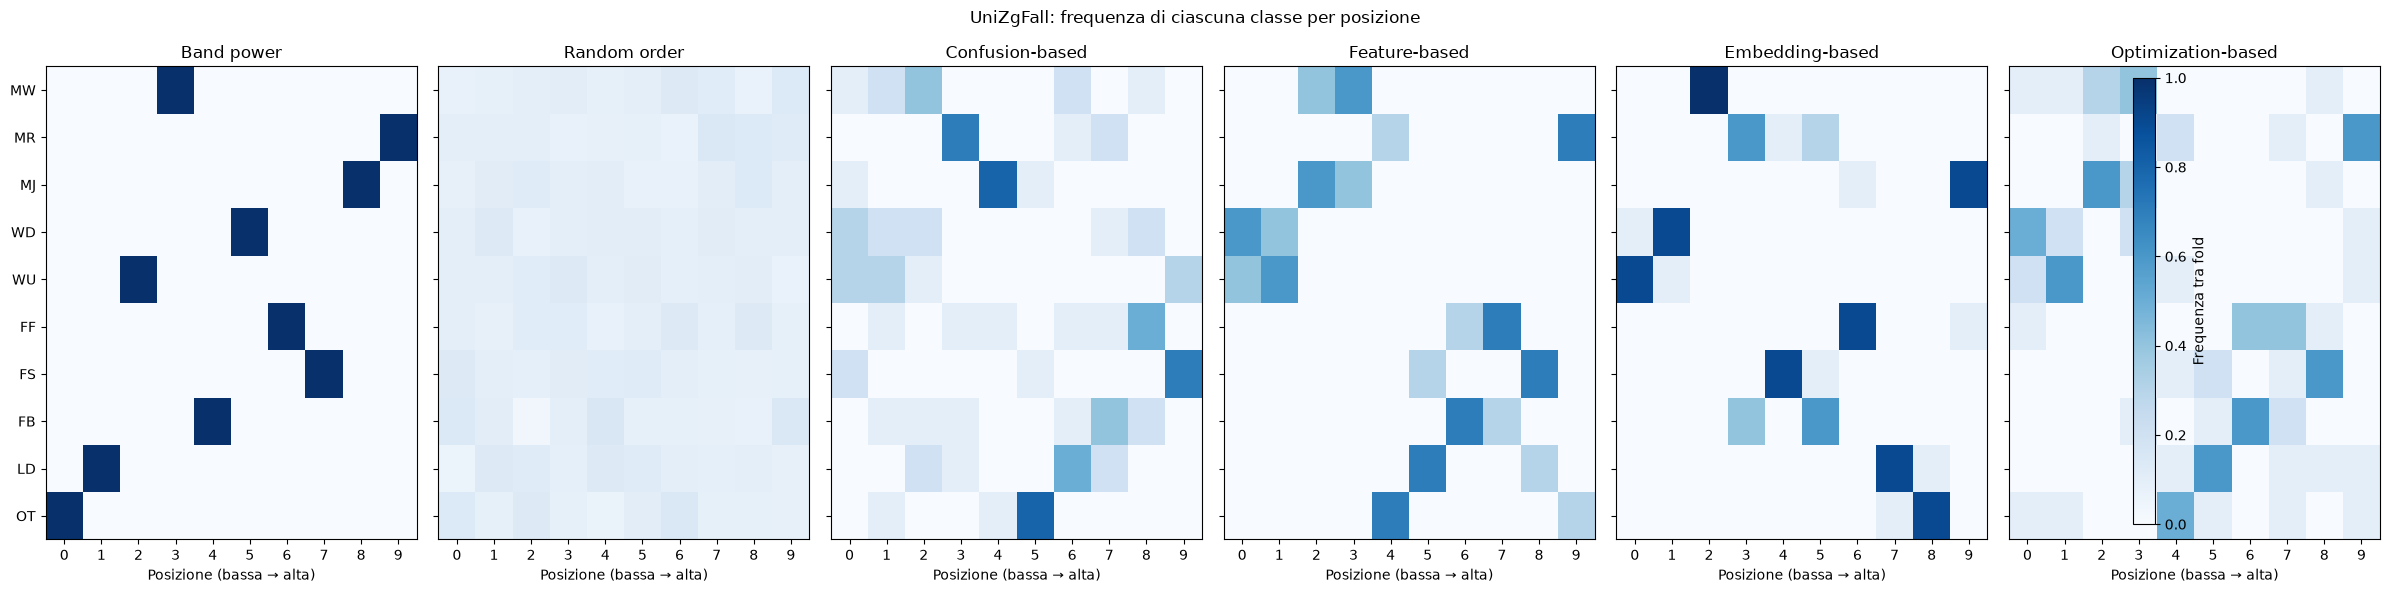

/tmp/ipykernel_30128/3664761437.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


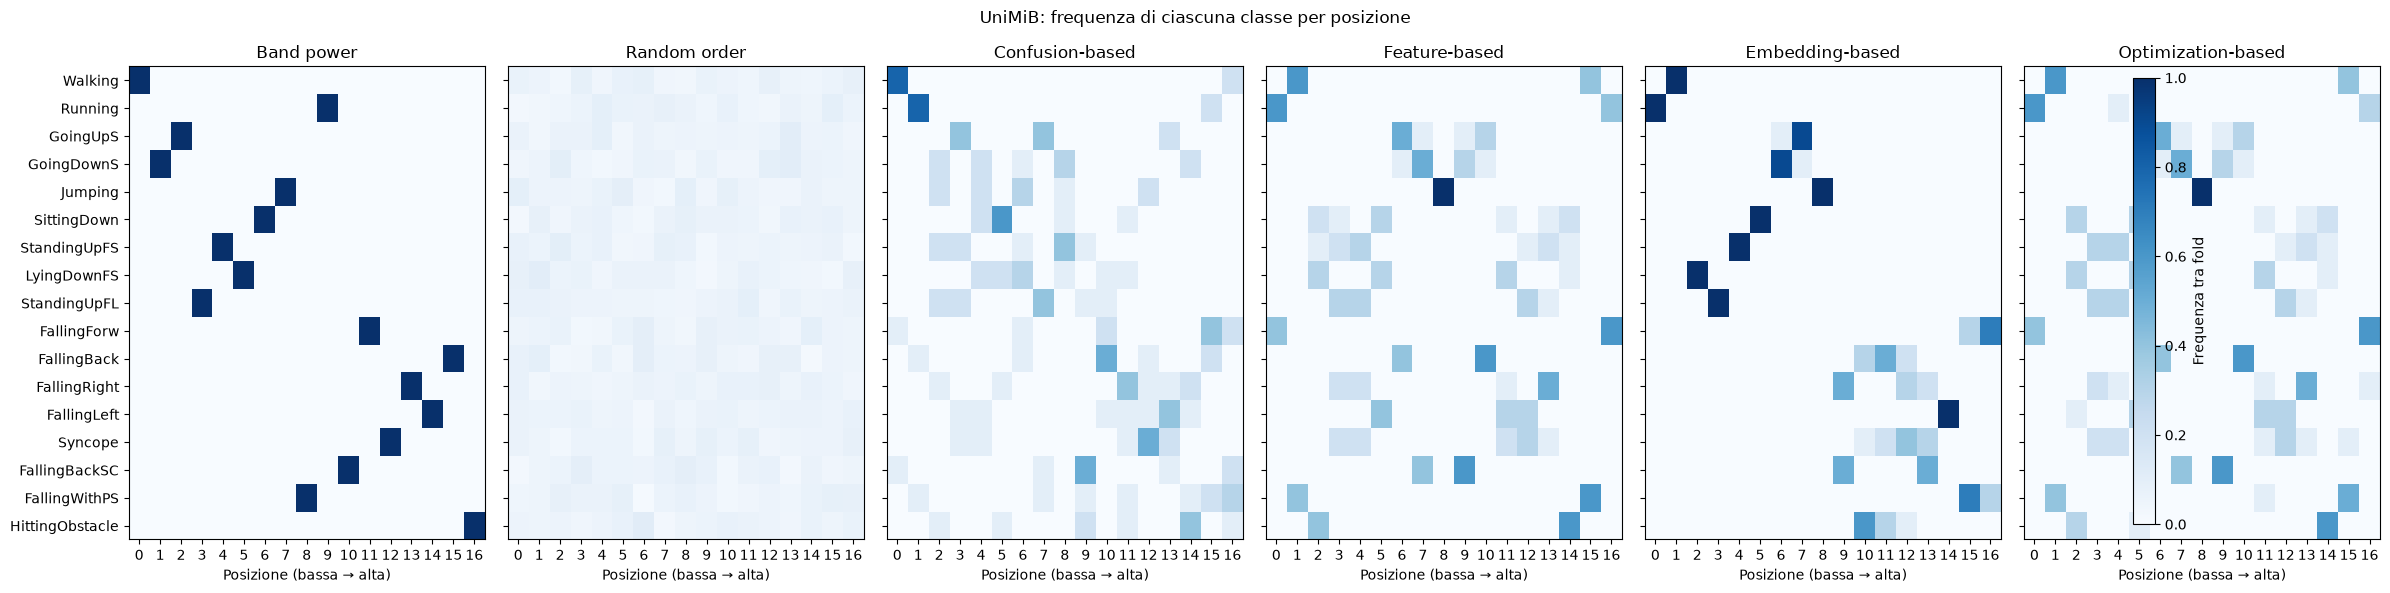

In [24]:
import importlib
benchmark = importlib.reload(benchmark)
if "all_orders" not in globals():
    saved_orders = RESULTS_DIR / "all_class_orders.csv"
    if saved_orders.is_file():
        all_orders = pd.read_csv(saved_orders)
        print("all_orders ricostruito dai risultati CSV salvati")
    else:
        raise NameError("all_orders non disponibile e nessun all_class_orders.csv presente")
elif all_orders is None or all_orders.empty:
    saved_orders = RESULTS_DIR / "all_class_orders.csv"
    if saved_orders.is_file():
        all_orders = pd.read_csv(saved_orders)
        print("all_orders ricostruito dai risultati CSV salvati")
if "contexts" not in globals():
    contexts = {}
for dataset in DATASETS_TO_RUN:
    if dataset not in contexts:
        contexts[dataset] = benchmark.load_dataset_context(PROJECT_DIR, dataset)
    if QUICK_TEST:
        contexts[dataset] = benchmark.limit_context(contexts[dataset], QUICK_OUTER_FOLD_LIMIT)
frequency, stability, class_ranks = benchmark.order_stability(all_orders)
display(stability.sort_values(["dataset", "mean_pairwise_kendall_tau"], ascending=[True, False]))
fixed_checks = stability[stability.method == "Band power"]
if not (fixed_checks.mean_pairwise_kendall_tau >= 1 - 1e-12).all():
    raise AssertionError("Band power non è costante tra i fold")

for dataset in DATASETS_TO_RUN:
    part = frequency[frequency.dataset == dataset]
    methods = list(dict.fromkeys(part.method))
    fig, axes = plt.subplots(1, len(methods), figsize=(4 * len(methods), 6), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, method in zip(axes, methods):
        matrix = part[part.method == method].pivot(
            index="class_name", columns="position", values="frequency"
        ).reindex(contexts[dataset].class_names)
        image = ax.imshow(matrix.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="Blues")
        ax.set_title(method)
        ax.set_xlabel("Posizione (bassa → alta)")
        ax.set_xticks(range(matrix.shape[1]))
        if ax is axes[0]:
            ax.set_yticks(range(len(matrix.index)), matrix.index)
        else:
            ax.tick_params(axis="y", labelleft=False)
    fig.suptitle(f"{dataset}: frequenza di ciascuna classe per posizione")
    fig.colorbar(image, ax=axes, fraction=0.012, pad=0.02, label="Frequenza tra fold")
    fig.tight_layout()
    if SAVE_PNG:
        fig.savefig(RESULTS_DIR / f"{dataset}_position_frequency.png", dpi=180, bbox_inches="tight")
    plt.show()


## Metriche, boxplot e confronto robusto rispetto al caso

I boxplot mostrano la distribuzione sui fold per tutti i metodi. Nel grafico seguente ogni punto è il delta medio rispetto alla media delle baseline Random order multi-seed. Le barre verticali sono intervalli bootstrap al 95% ottenuti ricampionando fold e ripetizioni casuali; il test Wilcoxon appaiato è riportato separatamente. Un intervallo che esclude zero è evidenza più robusta di vantaggio o svantaggio rispetto al caso.


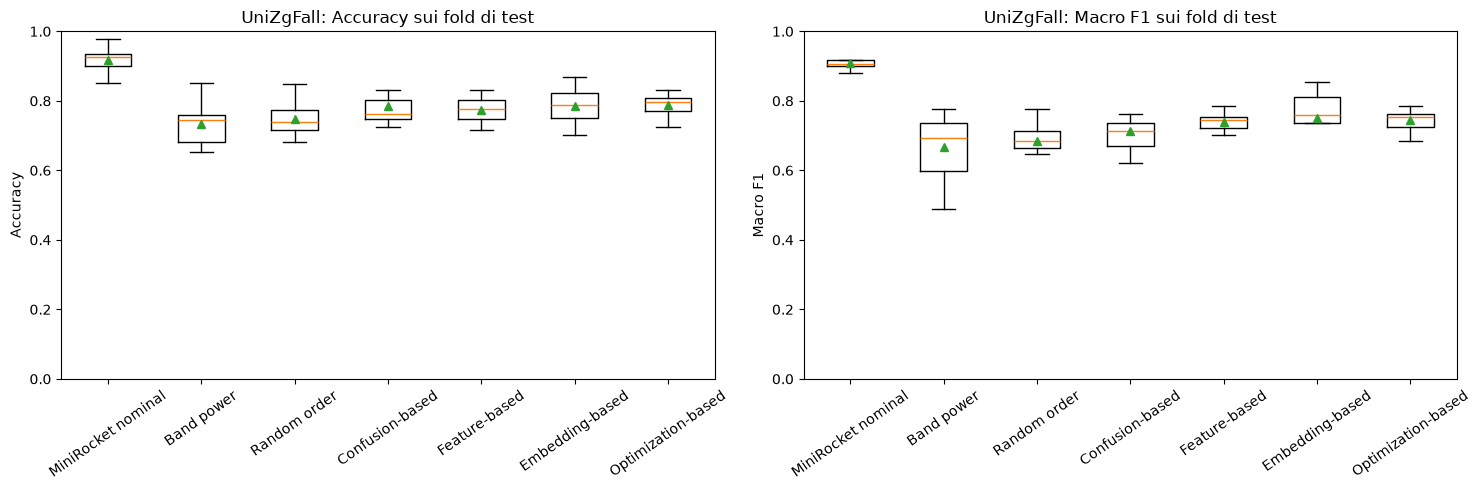

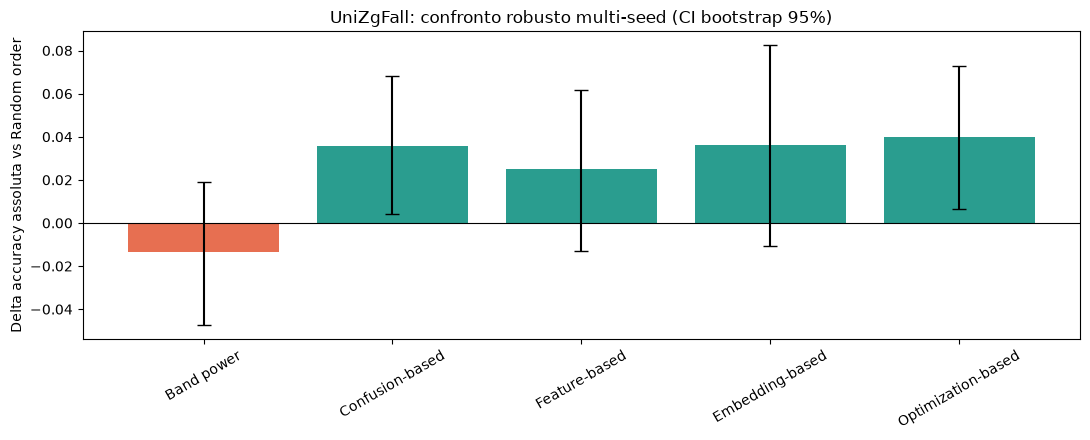

,method,accuracy_paired_delta_mean,accuracy_bootstrap_ci_low,accuracy_bootstrap_ci_high,wilcoxon_p_value,bootstrap_positive_probability,folds_better_than_random_mean
0,Band power,-0.013522,-0.047271,0.019149,0.322266,0.2003,4
1,Confusion-based,0.035830,0.004070,0.068085,0.013672,0.9838,9
2,Feature-based,0.025099,-0.012766,0.061841,0.105469,0.9062,8
3,Embedding-based,0.036154,-0.010638,0.082424,0.105469,0.9342,8
4,Optimization-based,0.040086,0.006383,0.072757,0.009766,0.9896,9


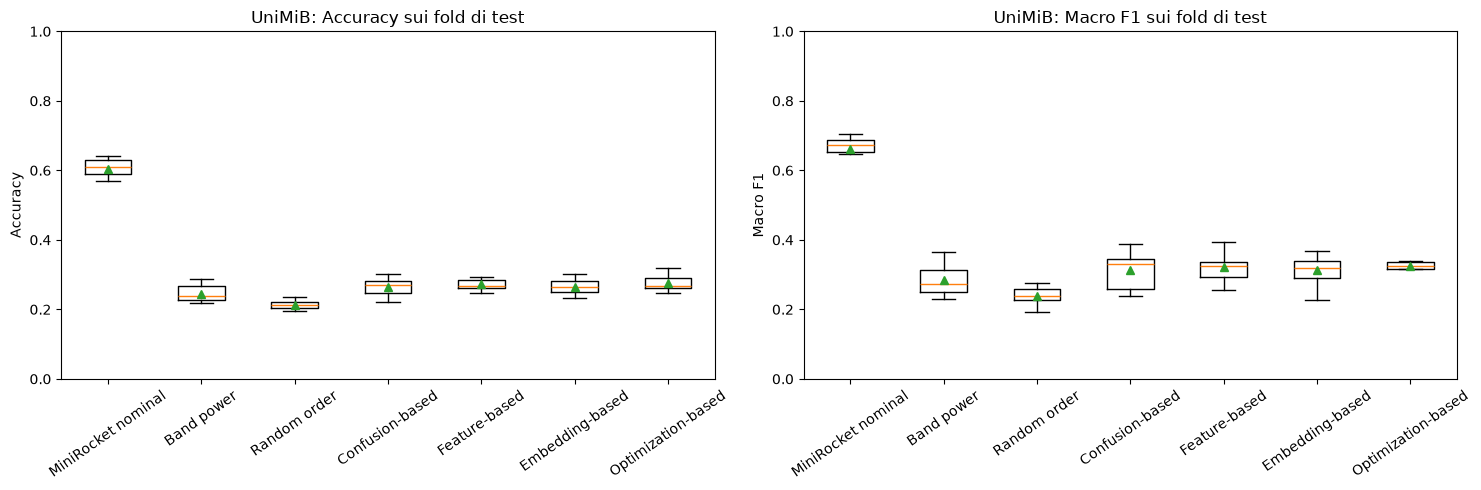

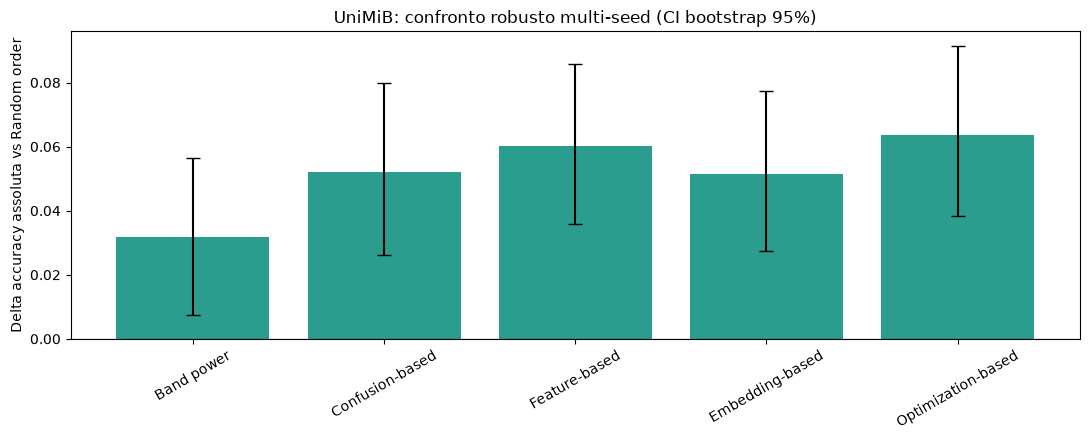

,method,accuracy_paired_delta_mean,accuracy_bootstrap_ci_low,accuracy_bootstrap_ci_high,wilcoxon_p_value,bootstrap_positive_probability,folds_better_than_random_mean
5,Band power,0.031818,0.007576,0.056566,0.003906,0.9962,9
6,Confusion-based,0.052020,0.026263,0.079798,0.001953,0.9998,10
7,Feature-based,0.060101,0.035859,0.085859,0.001953,1.0000,10
8,Embedding-based,0.051515,0.027273,0.077273,0.001953,1.0000,10
9,Optimization-based,0.063636,0.038384,0.091414,0.001953,1.0000,10


In [25]:
for dataset in DATASETS_TO_RUN:
    part = all_fold_metrics[all_fold_metrics.dataset == dataset]
    methods = [benchmark.NOMINAL_METHOD, *[m for m in benchmark.ALL_METHODS if m in part.method.unique()]]
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for ax, metric, title in zip(axes, ("accuracy", "f1_macro"), ("Accuracy", "Macro F1")):
        samples = [part.loc[part.method == method, metric].to_numpy() for method in methods]
        ax.boxplot(samples, tick_labels=methods, showmeans=True, showfliers=False)
        ax.set_title(f"{dataset}: {title} sui fold di test")
        ax.set_ylabel(title)
        ax.set_ylim(0, 1)
        ax.tick_params(axis="x", labelrotation=35)
    fig.tight_layout()
    if SAVE_PNG:
        fig.savefig(RESULTS_DIR / f"{dataset}_metrics_boxplot.png", dpi=180, bbox_inches="tight")
    plt.show()

    robust_csv = RESULTS_DIR / "accuracy_delta_vs_random_robust.csv"
    if "robust_random_accuracy" not in globals() or not isinstance(robust_random_accuracy, pd.DataFrame):
        robust_random_accuracy = pd.read_csv(robust_csv) if robust_csv.is_file() else pd.DataFrame()
    elif robust_random_accuracy.empty and robust_csv.is_file():
        robust_random_accuracy = pd.read_csv(robust_csv)
    delta = robust_random_accuracy[robust_random_accuracy.dataset == dataset] if not robust_random_accuracy.empty else pd.DataFrame()
    if delta.empty:
        print(f"{dataset}: confronto robusto CSV/non disponibile; eseguire Random order multi-seed")
        continue
    fig, ax = plt.subplots(figsize=(11, 4.5))
    colors = ["#2a9d8f" if value >= 0 else "#e76f51" for value in delta.accuracy_paired_delta_mean]
    errors = np.vstack([
        delta.accuracy_paired_delta_mean - delta.accuracy_bootstrap_ci_low,
        delta.accuracy_bootstrap_ci_high - delta.accuracy_paired_delta_mean,
    ])
    ax.bar(delta.method, delta.accuracy_paired_delta_mean, yerr=errors, capsize=5, color=colors)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel("Delta accuracy assoluta vs Random order")
    ax.set_title(f"{dataset}: confronto robusto multi-seed (CI bootstrap 95%)")
    ax.tick_params(axis="x", labelrotation=30)
    fig.tight_layout()
    if SAVE_PNG:
        fig.savefig(RESULTS_DIR / f"{dataset}_delta_vs_random_robust.png", dpi=180, bbox_inches="tight")
    plt.show()
    display(delta[["method", "accuracy_paired_delta_mean", "accuracy_bootstrap_ci_low", "accuracy_bootstrap_ci_high", "wilcoxon_p_value", "bootstrap_positive_probability", "folds_better_than_random_mean"]])


## Ricerca Optimization-based

La cella visualizza esclusivamente metriche della validation interna usate dal simulated annealing: non sono risultati di test. Serve a verificare quali permutazioni sono state proposte e quale score le ha guidate. La cella opera solo se Optimization-based è già stato eseguito.


,dataset,fold,step,inner_macro_f1,order,current_macro_f1,best_macro_f1,accepted
0,UniZgFall,1,0,0.734817,"[3, 4, 2, 0, 9, 8, 7, 5, 6, 1]",NaN,NaN,NaN
1,UniZgFall,1,1,0.727949,"[3, 2, 4, 0, 9, 8, 7, 5, 6, 1]",0.727949,0.734817,True
2,UniZgFall,1,2,0.702755,"[3, 2, 6, 0, 9, 8, 7, 5, 4, 1]",0.702755,0.734817,True
3,UniZgFall,1,3,0.673204,"[5, 2, 6, 0, 9, 8, 7, 3, 4, 1]",0.702755,0.734817,False
4,UniZgFall,1,4,0.694241,"[3, 2, 6, 0, 7, 8, 9, 5, 4, 1]",0.702755,0.734817,False
...,...,...,...,...,...,...,...,...
95,UniMiB,10,0,0.331520,"[1, 0, 6, 5, 8, 7, 3, 2, 4, 14, 10, 11, 12, 13...",NaN,NaN,NaN
96,UniMiB,10,1,0.216708,"[1, 0, 6, 13, 8, 7, 3, 2, 4, 14, 10, 11, 12, 5...",0.331520,0.331520,False
97,UniMiB,10,2,0.333859,"[1, 0, 5, 6, 8, 7, 3, 2, 4, 14, 10, 11, 12, 13...",0.333859,0.333859,True
98,UniMiB,10,3,0.273908,"[9, 0, 5, 6, 8, 7, 3, 2, 4, 14, 10, 11, 12, 13...",0.333859,0.333859,False


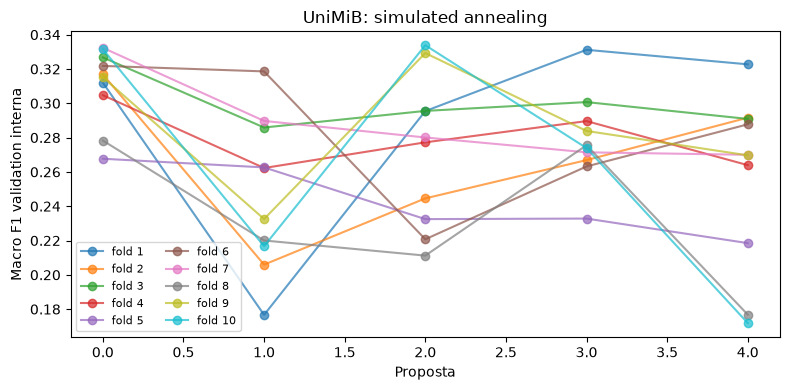

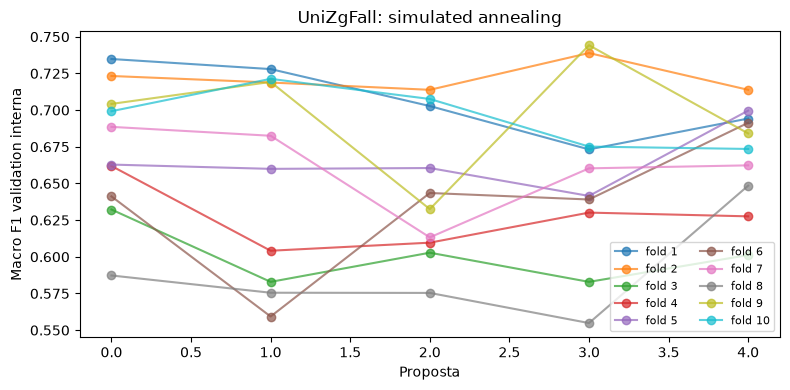

In [26]:
trace_frames = [
    r["Optimization-based"]["optimization_trace"]
    for r in benchmark_results.values()
    if "Optimization-based" in r and not r["Optimization-based"]["optimization_trace"].empty
]
if trace_frames:
    optimization_trace = pd.concat(trace_frames, ignore_index=True)
    display(optimization_trace)
    for dataset, part in optimization_trace.groupby("dataset"):
        fig, ax = plt.subplots(figsize=(8, 4))
        for fold, fold_part in part.groupby("fold"):
            ax.plot(fold_part.step, fold_part.inner_macro_f1, marker="o", alpha=0.7, label=f"fold {fold}")
        ax.set_xlabel("Proposta")
        ax.set_ylabel("Macro F1 validation interna")
        ax.set_title(f"{dataset}: simulated annealing")
        ax.legend(ncol=2, fontsize=8)
        fig.tight_layout()
        if SAVE_PNG:
            fig.savefig(RESULTS_DIR / f"{dataset}_optimization_trace.png", dpi=180, bbox_inches="tight")
        plt.show()
else:
    print("Optimization-based non ancora eseguito.")


## Esportazione finale

La cella scrive soltanto tabelle CSV aggregate. I grafici precedenti hanno eventualmente già salvato PNG. Nessun HTML, notebook renderizzato o altro formato viene generato dal codice. La cartella di output può essere rimossa e ricreata senza modificare i dati sorgente.


In [27]:
if SAVE_CSV:
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    all_fold_metrics.to_csv(RESULTS_DIR / "all_fold_metrics.csv", index=False)
    all_orders.to_csv(RESULTS_DIR / "all_class_orders.csv", index=False)
    frequency.to_csv(RESULTS_DIR / "order_position_frequency.csv", index=False)
    stability.to_csv(RESULTS_DIR / "order_stability.csv", index=False)
    class_ranks.to_csv(RESULTS_DIR / "class_rank_stability.csv", index=False)
    metric_delta_nominal.to_csv(RESULTS_DIR / "accuracy_delta_vs_nominal.csv", index=False)
    random_delta_accuracy.to_csv(RESULTS_DIR / "accuracy_delta_vs_random.csv", index=False)
    robust_random_accuracy.to_csv(RESULTS_DIR / "accuracy_delta_vs_random_robust.csv", index=False)
    random_repetition_table.to_csv(RESULTS_DIR / "random_order_repetitions.csv", index=False)
print("Output CSV:", RESULTS_DIR if SAVE_CSV else "disabilitati")


Output CSV: /home/agrume/Desktop/projects/thesis/ordinal_ordering_benchmark/results
